# LODES: how the US commuting data counts people, the metros of the study

LODES (LEHD Origin-Destination Employment Statistics) is the Census Bureau's yearly
table of where workers live and where they work. It is not a survey. The counts come
from administrative records: state unemployment insurance wage records matched to the
employer's address, and the worker's home address from federal tax and benefit records.
A row is therefore a *job*, located by the workplace address and the home address, not
a person answering a question about commuting. Everything is published on 2020 census
blocks, the smallest census unit, with noise added for confidentiality.

What this means for us:

- **Who is counted.** Jobs covered by unemployment insurance plus federal civilian
  jobs. Not counted: the self-employed, military, informal work, and jobs whose
  home or work address could not be placed.
- **Jobs, not people.** A person with two jobs is two rows. The `JT01` files keep only
  the primary job of each worker, one row per worker, which is the one for commuting.
  `JT00` has all jobs.
- **Home is the registered address**, not where the person was on a given day, and
  there is no travel mode or working-from-home flag.
- **One file per state.** The `main` file has jobs whose worker lives in the same
  state as the workplace; the `aux` file has jobs in the state whose worker lives in
  another state.

| Step | What we do |
|---|---|
| 1. Files and counts | Download the 2023 OD files and the block crosswalk for the home state of each metro; how many jobs, workers and blocks |
| 2. Unit level and the city | What a block is, how blocks nest in tracts, counties, places and metropolitan areas; the three ways to draw each city, with counts and a map |
| 3. The metropolitan area | Why it is the unit; the complete area across state lines, with the other states of each metro added; workers and blocks saved for the next notebooks |

The metros are New York, the densest US city, Houston, among the most car-dependent large ones,
and then Chicago, Seattle and Phoenix, which fill the range between them in transit, congestion and
grid carbon.

In [1]:
import gzip
import time
import urllib.request
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Parameters

Files come from `lehd.ces.census.gov/data/lodes/LODES8/`. 2023 is the latest year
released (December 2025). The place and metropolitan area of each city are looked up
by name in the crosswalk in step 2, so no code is typed here.

In [2]:
YEAR = 2023
LODES_URL = "https://lehd.ces.census.gov/data/lodes/LODES8"
DATA = Path("/scratch/project_2010423/data/lodes")
DATA.mkdir(parents=True, exist_ok=True)

CITIES = {
    "New York": {"state": "ny", "place_name": "New York city", "cbsa_name": "New York-Newark-Jersey City"},
    "Houston": {"state": "tx", "place_name": "Houston city", "cbsa_name": "Houston-"},
    "Chicago": {"state": "il", "place_name": "Chicago city", "cbsa_name": "Chicago-Naperville"},
    "Seattle": {"state": "wa", "place_name": "Seattle city", "cbsa_name": "Seattle-Tacoma"},
    "Phoenix": {"state": "az", "place_name": "Phoenix city", "cbsa_name": "Phoenix-Mesa"},
}
JOB_TYPES = {"JT00": "all jobs", "JT01": "primary jobs (one per worker)"}
PARTS = {"main": "worker lives in the same state", "aux": "worker lives in another state"}

## 1. Files and counts

One OD file per state, part and job type, plus the state's crosswalk, which gives
every 2020 block its tract, county, place, metropolitan area and coordinates. Files
already on disk are reused.

In [3]:
def lodes_file(state, kind):
    # Download one LODES file for a state if it is not on disk yet; return its path.
    if kind == "xwalk":
        name = f"{state}_xwalk.csv.gz"
        url = f"{LODES_URL}/{state}/{name}"
    else:
        part, job_type = kind
        name = f"{state}_od_{part}_{job_type}_{YEAR}.csv.gz"
        url = f"{LODES_URL}/{state}/od/{name}"
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path


files = []
for city, spec in CITIES.items():
    files.append({"city": city, "file": lodes_file(spec["state"], "xwalk").name, "content": "block crosswalk"})
    for part in PARTS:
        for job_type in JOB_TYPES:
            path = lodes_file(spec["state"], (part, job_type))
            files.append({"city": city, "file": path.name, "content": f"OD, {PARTS[part]}, {JOB_TYPES[job_type]}"})
files = pd.DataFrame(files)
files["MB"] = [round((DATA / name).stat().st_size / 1e6, 1) for name in files["file"]]
files

,city,file,content,MB
0,New York,ny_xwalk.csv.gz,block crosswalk,5.2
1,New York,ny_od_main_JT00_2023.csv.gz,"OD, worker lives in the same state, all jobs",45.0
2,New York,ny_od_main_JT01_2023.csv.gz,"OD, worker lives in the same state, primary jo...",41.1
3,New York,ny_od_aux_JT00_2023.csv.gz,"OD, worker lives in another state, all jobs",5.6
4,New York,ny_od_aux_JT01_2023.csv.gz,"OD, worker lives in another state, primary job...",5.1
5,Houston,tx_xwalk.csv.gz,block crosswalk,11.4
6,Houston,tx_od_main_JT00_2023.csv.gz,"OD, worker lives in the same state, all jobs",72.9
7,Houston,tx_od_main_JT01_2023.csv.gz,"OD, worker lives in the same state, primary jo...",68.0
8,Houston,tx_od_aux_JT00_2023.csv.gz,"OD, worker lives in another state, all jobs",1.8
9,Houston,tx_od_aux_JT01_2023.csv.gz,"OD, worker lives in another state, primary job...",1.7


The columns of an OD file: the work block, the home block, total jobs `S000`, and
breakdowns by age (`SA`), earnings (`SE`) and industry group (`SI`). Blocks are 15-digit
codes: state (2), county (3), tract (6), block (4).

In [4]:
example = pd.read_csv(DATA / f"ny_od_main_JT01_{YEAR}.csv.gz", nrows=5, dtype={"w_geocode": str, "h_geocode": str})
example

,w_geocode,h_geocode,S000,SA01,SA02,SA03,SE01,SE02,SE03,SI01,SI02,SI03,createdate
0,360010001001003,360010135052000,1,0,1,0,0,0,1,0,1,0,20251202
1,360010001001003,360010136023003,1,0,1,0,0,0,1,0,0,1,20251202
2,360010001001003,360050147012001,1,0,1,0,0,0,1,0,0,1,20251202
3,360010001001003,360359711003007,1,0,1,0,0,0,1,0,0,1,20251202
4,360010001001003,361130708012024,1,0,1,0,0,0,1,0,0,1,20251202


In [5]:
def read_od(state, part, job_type):
    # One OD file: work block, home block, number of jobs.
    path = DATA / f"{state}_od_{part}_{job_type}_{YEAR}.csv.gz"
    return pd.read_csv(path, usecols=["w_geocode", "h_geocode", "S000"], dtype={"w_geocode": str, "h_geocode": str})


od = {}
counts = []
for city, spec in CITIES.items():
    for job_type in JOB_TYPES:
        for part in PARTS:
            started = time.time()
            table = read_od(spec["state"], part, job_type)
            od[(city, job_type, part)] = table
            counts.append({"city": city, "job_type": JOB_TYPES[job_type], "part": PARTS[part],
                           "rows (block pairs)": len(table), "jobs": table["S000"].sum(),
                           "work blocks": table["w_geocode"].nunique(), "home blocks": table["h_geocode"].nunique(),
                           "seconds": round(time.time() - started)})
counts = pd.DataFrame(counts)
counts

,city,job_type,part,rows (block pairs),jobs,work blocks,home blocks,seconds
0,New York,all jobs,worker lives in the same state,7720403,8578463,107365,223025,5
1,New York,all jobs,worker lives in another state,809356,832893,48948,240113,1
2,New York,primary jobs (one per worker),worker lives in the same state,7055595,7789260,105558,222317,5
3,New York,primary jobs (one per worker),worker lives in another state,745983,767838,46758,224269,1
4,Houston,all jobs,worker lives in the same state,12039831,13335103,168281,431141,9
5,Houston,all jobs,worker lives in another state,206193,207970,41825,153495,0
6,Houston,primary jobs (one per worker),worker lives in the same state,11225546,12415012,165844,429485,8
7,Houston,primary jobs (one per worker),worker lives in another state,189444,191027,39685,142227,0
8,Chicago,all jobs,worker lives in the same state,5250037,5653290,91500,263469,4
9,Chicago,all jobs,worker lives in another state,286018,290537,34838,156984,0


The state totals: primary jobs are the number of workers with a job in the state. The
share of them living in another state is what the `aux` part adds, and it matters
most for New York, where New Jersey and Connecticut commuters work in Manhattan.

In [6]:
totals = counts.groupby(["city", "job_type"])["jobs"].sum().unstack("job_type")
totals["jobs per worker"] = totals["all jobs"] / totals["primary jobs (one per worker)"]
aux = counts.loc[counts["part"] == PARTS["aux"]].set_index(["city", "job_type"])["jobs"].unstack("job_type")
totals["share of workers living out of state"] = aux["primary jobs (one per worker)"] / totals["primary jobs (one per worker)"]
totals.round(3)

job_type,all jobs,primary jobs (one per worker),jobs per worker,share of workers living out of state
city,,,,
Chicago,5943827,5503955,1.080,0.049
Houston,13543073,12606039,1.074,0.015
New York,9411356,8557098,1.100,0.090
Phoenix,3140901,2935350,1.070,0.016
Seattle,3519988,3283987,1.072,0.031


## 2. Unit level and the city

The crosswalk has one row per 2020 block in the state, with the units it belongs to
and the coordinates of its internal point. The units that matter here, from small to
large:

| Column | Unit | What it is |
|---|---|---|
| `tabblk2020` | block | smallest census unit, often one city block; a few hundred people at most |
| `bgrp` | block group | 600 to 3,000 people |
| `trct` | tract | 1,200 to 8,000 people, designed to be stable neighbourhoods |
| `cty` | county | administrative; New York City is five counties, Houston spans three |
| `stplc` | place | the incorporated city, its legal limits |
| `cbsa` | metropolitan area | counties tied together by commuting, defined by the federal government |

So there are three ways to say "New York" or "Houston": the place (city limits), the
county or counties, or the metropolitan area. The map shows the blocks of each, and
the table counts the jobs under each definition.

In [7]:
XWALK_COLUMNS = ["tabblk2020", "cty", "ctyname", "trct", "bgrp", "stplc", "stplcname", "cbsa", "cbsaname", "blklatdd", "blklondd"]
xwalk = {}
for city, spec in CITIES.items():
    table = pd.read_csv(DATA / f"{spec['state']}_xwalk.csv.gz", usecols=XWALK_COLUMNS, dtype={c: str for c in XWALK_COLUMNS[:9]})
    xwalk[city] = table
    print(f"{city}: {len(table):,} blocks in the state crosswalk, {table['trct'].nunique():,} tracts, {table['cty'].nunique()} counties")
xwalk["New York"].head()

New York: 288,819 blocks in the state crosswalk, 5,411 tracts, 62 counties


Houston: 668,757 blocks in the state crosswalk, 6,896 tracts, 254 counties


Chicago: 369,978 blocks in the state crosswalk, 3,265 tracts, 102 counties


Seattle: 158,093 blocks in the state crosswalk, 1,784 tracts, 39 counties


Phoenix: 155,444 blocks in the state crosswalk, 1,765 tracts, 15 counties


,tabblk2020,cty,ctyname,trct,bgrp,cbsa,cbsaname,stplc,stplcname,blklatdd,blklondd
0,360010001001000,36001,"Albany County, NY",36001000100,360010001001,10580,"Albany-Schenectady-Troy, NY",3601000,"Albany city, NY",42.669254,-73.726498
1,360010001001001,36001,"Albany County, NY",36001000100,360010001001,10580,"Albany-Schenectady-Troy, NY",3601000,"Albany city, NY",42.668937,-73.730992
2,360010001001002,36001,"Albany County, NY",36001000100,360010001001,10580,"Albany-Schenectady-Troy, NY",3601000,"Albany city, NY",42.667434,-73.733070
3,360010001001003,36001,"Albany County, NY",36001000100,360010001001,10580,"Albany-Schenectady-Troy, NY",3601000,"Albany city, NY",42.669283,-73.731587
4,360010001001004,36001,"Albany County, NY",36001000100,360010001001,10580,"Albany-Schenectady-Troy, NY",3601000,"Albany city, NY",42.670544,-73.734188


The place and the metropolitan area of each city, found by name in the crosswalk, and
the counties the place touches.

In [8]:
definitions = {}
for city, spec in CITIES.items():
    table = xwalk[city]
    place = table.loc[table["stplcname"].str.startswith(spec["place_name"], na=False), ["stplc", "stplcname"]].drop_duplicates()
    cbsa = table.loc[table["cbsaname"].str.startswith(spec["cbsa_name"], na=False), ["cbsa", "cbsaname"]].drop_duplicates()
    assert len(place) == 1 and len(cbsa) == 1, (city, place, cbsa)
    place_code, cbsa_code = place["stplc"].iloc[0], cbsa["cbsa"].iloc[0]
    counties = table.loc[table["stplc"] == place_code, "ctyname"].value_counts()
    definitions[city] = {"place": place_code, "place_name": place["stplcname"].iloc[0],
                         "cbsa": cbsa_code, "cbsa_name": cbsa["cbsaname"].iloc[0],
                         "counties_of_place": list(counties.index)}
    print(f"{city}: place {place_code} '{definitions[city]['place_name']}', metropolitan area {cbsa_code} '{definitions[city]['cbsa_name']}'")
    print("  blocks of the place by county:", counties.to_dict())

New York: place 3651000 'New York city, NY', metropolitan area 35620 'New York-Newark-Jersey City, NY-NJ'
  blocks of the place by county: {'Queens County, NY': 14094, 'Kings County, NY': 9855, 'Bronx County, NY': 5320, 'Richmond County, NY': 4672, 'New York County, NY': 4043}


Houston: place 4835000 'Houston city, TX', metropolitan area 26420 'Houston-Pasadena-The Woodlands, TX'
  blocks of the place by county: {'Harris County, TX': 28599, 'Fort Bend County, TX': 717, 'Montgomery County, TX': 194, 'Waller County, TX': 2}


Chicago: place 1714000 'Chicago city, IL', metropolitan area 16980 'Chicago-Naperville-Elgin, IL-IN'
  blocks of the place by county: {'Cook County, IL': 38804, 'DuPage County, IL': 12}
Seattle: place 5363000 'Seattle city, WA', metropolitan area 42660 'Seattle-Tacoma-Bellevue, WA'
  blocks of the place by county: {'King County, WA': 10364}
Phoenix: place 0455000 'Phoenix city, AZ', metropolitan area 38060 'Phoenix-Mesa-Chandler, AZ'
  blocks of the place by county: {'Maricopa County, AZ': 18458}


Jobs under each definition, from the primary-job files (one row per worker). A worker
is "inside" when both home and work blocks fall in the unit; the other two columns
count workers by workplace only and by home only. Note that the metropolitan area of
New York continues into New Jersey, Pennsylvania and Connecticut, whose blocks are in
other states' files, so its row here is the New York State part only.

In [9]:
def jobs_by_definition(city):
    # Workers (primary jobs) by workplace, by home, and with both inside, for the three definitions of the city.
    table = xwalk[city].set_index("tabblk2020")
    spec = definitions[city]
    units = {
        "place (city limits)": table["stplc"] == spec["place"],
        "counties of the place": table["cty"].isin(table.loc[table["stplc"] == spec["place"], "cty"].unique()),
        "metropolitan area (state part)": table["cbsa"] == spec["cbsa"],
    }
    workers = pd.concat([od[(city, "JT01", "main")], od[(city, "JT01", "aux")]])
    rows = []
    for name, inside in units.items():
        inside_blocks = set(inside.index[inside])
        at_work = workers["w_geocode"].isin(inside_blocks)
        at_home = workers["h_geocode"].isin(inside_blocks)
        rows.append({"definition": name, "blocks": len(inside_blocks),
                     "workers by workplace": workers.loc[at_work, "S000"].sum(),
                     "workers by home": workers.loc[at_home, "S000"].sum(),
                     "workers with both inside": workers.loc[at_work & at_home, "S000"].sum()})
    rows = pd.DataFrame(rows).set_index("definition")
    rows["share of the place's workforce living inside"] = rows["workers with both inside"] / rows["workers by workplace"]
    return rows


for city in CITIES:
    print(city)
    display(jobs_by_definition(city).round(2))

New York


,blocks,workers by workplace,workers by home,workers with both inside,share of the place's workforce living inside
definition,,,,,
place (city limits),37984,4142287,3181672,2853194,0.69
counties of the place,37984,4142287,3181672,2853194,0.69
metropolitan area (state part),100115,5800122,5001519,4888937,0.84


Houston


,blocks,workers by workplace,workers by home,workers with both inside,share of the place's workforce living inside
definition,,,,,
place (city limits),29512,1789039,884754,578927,0.32
counties of the place,69259,2843342,2605585,2216604,0.78
metropolitan area (state part),91124,3115237,3016105,2664779,0.86


Chicago


,blocks,workers by workplace,workers by home,workers with both inside,share of the place's workforce living inside
definition,,,,,
place (city limits),38816,1359301,1088490,715474,0.53
counties of the place,98230,3073293,2592157,2276145,0.74
metropolitan area (state part),150077,4000999,3733316,3622359,0.91


Seattle


,blocks,workers by workplace,workers by home,workers with both inside,share of the place's workforce living inside
definition,,,,,
place (city limits),10364,613163,363020,219909,0.36
counties of the place,27685,1409178,1059091,904945,0.64
metropolitan area (state part),50254,1990291,1812880,1693891,0.85


Phoenix


,blocks,workers by workplace,workers by home,workers with both inside,share of the place's workforce living inside
definition,,,,,
place (city limits),18458,959509,698099,389987,0.41
counties of the place,61427,2161202,1927948,1842888,0.85
metropolitan area (state part),74236,2230479,2119346,2039140,0.91


The map: every block of the metropolitan area (state part) as a point at its internal
point, in grey; the counties of the place outlined by their blocks in a lighter blue;
the place itself in dark blue. The eye sees how much of the commuting region each
definition leaves out.

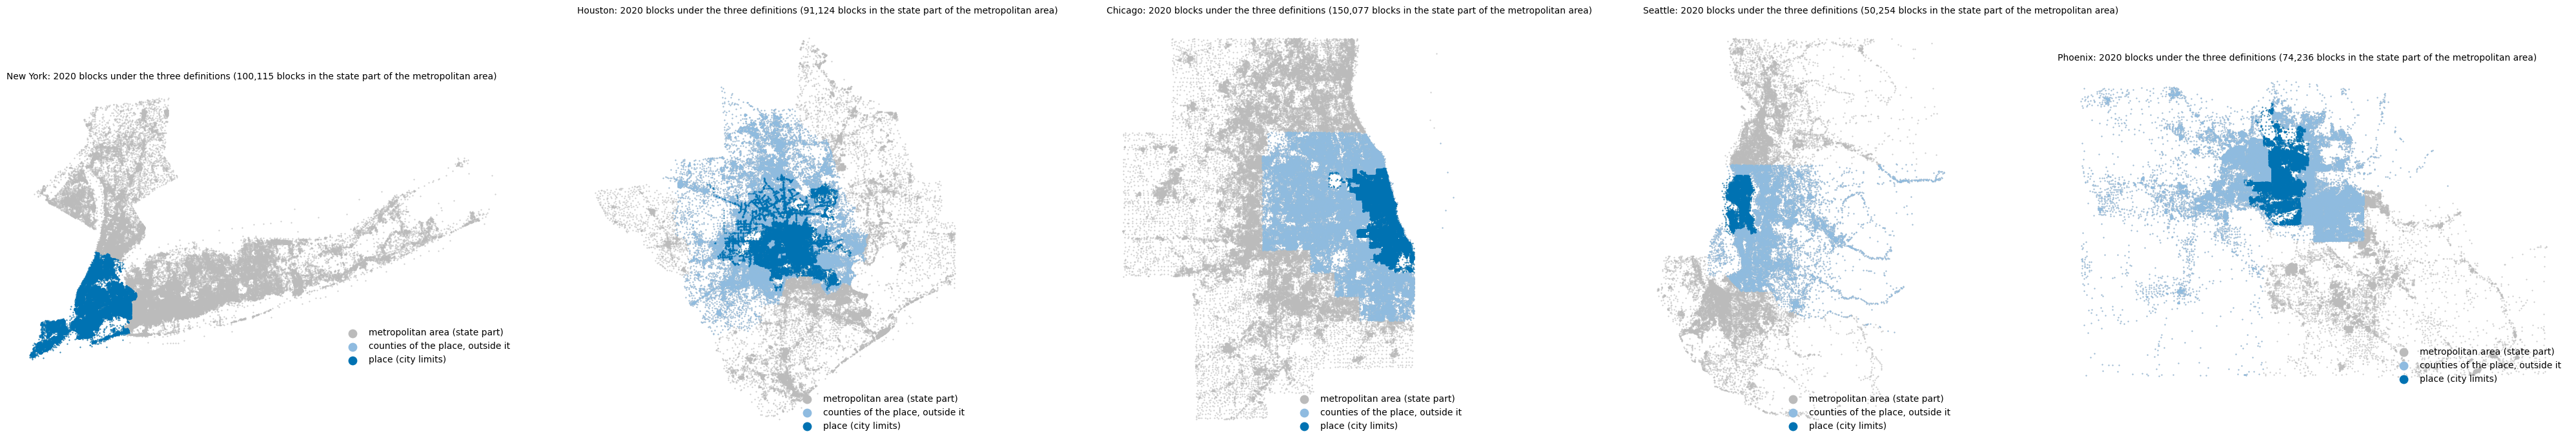

In [10]:
figure, axes = plt.subplots(ncols=len(CITIES), figsize=(8 * len(CITIES), 7))
for axis, city in zip(axes, CITIES):
    table = xwalk[city]
    spec = definitions[city]
    in_cbsa = table["cbsa"] == spec["cbsa"]
    in_place = table["stplc"] == spec["place"]
    in_counties = table["cty"].isin(table.loc[in_place, "cty"].unique())
    axis.scatter(table.loc[in_cbsa, "blklondd"], table.loc[in_cbsa, "blklatdd"], s=0.2, color="#bbbbbb", label="metropolitan area (state part)")
    axis.scatter(table.loc[in_counties & ~in_place, "blklondd"], table.loc[in_counties & ~in_place, "blklatdd"], s=0.2, color="#8fbbe0", label="counties of the place, outside it")
    axis.scatter(table.loc[in_place, "blklondd"], table.loc[in_place, "blklatdd"], s=0.2, color="#0072B2", label="place (city limits)")
    axis.set_aspect(1 / np.cos(np.radians(table.loc[in_place, "blklatdd"].mean())))
    axis.legend(frameon=False, loc="lower right", markerscale=20)
    axis.set_title(f"{city}: 2020 blocks under the three definitions ({in_cbsa.sum():,} blocks in the state part of the metropolitan area)", loc="left", fontsize=10)
    axis.set_axis_off()
figure.tight_layout()

## 3. The metropolitan area

The unit from here on is the metropolitan area, for three reasons that can be cited.

- **It is defined by commuting.** The federal standard (OMB, 2020 standards, delineations
  of July 2023) builds a metropolitan statistical area from the central counties of an
  urban core plus every adjacent county where at least 25 % of workers commute to the
  central counties, or 25 % of jobs are held by residents of them. So the area is, by
  construction, the territory within which commuting happens.
- **It is the same idea as the European definition.** The EU-OECD functional urban area
  (Dijkstra, Poelman and Veneri, 2019) is a city plus its commuting zone, the local units
  sending at least 15 % of their workforce to the city. The OECD applies it to the United
  States as well, and the GHS-FUA dataset extends it to the world, so the US and European
  cities of the paper rest on one concept.
- **It is what US accessibility work uses.** The Access Across America series (Owen and
  Levinson, Accessibility Observatory) computes block-level access and reports it by
  core-based statistical area.

New York's area under the 2023 delineation is New York and New Jersey. The New Jersey
main file adds commutes inside New Jersey, and the New Jersey aux file adds New Yorkers
working in New Jersey; the New York aux file already has New Jersey residents working in
New York. Each file covers a different combination of workplace state and residence
state, so stacking them counts nothing twice. Houston's area is entirely in Texas.

In [11]:
# Other states of each metropolitan area, from the state codes in the crosswalk name.
EXTRA_STATES = {"New York": ["nj"], "Houston": [], "Chicago": ["in"]   # the 2023 delineation of the Chicago area no longer includes Kenosha County, WI, "Seattle": [], "Phoenix": []}
RESULTS = Path("/scratch/project_2010423/carbon-advantage/commuting")

for city, states in EXTRA_STATES.items():
    for state in states:
        for kind in ["xwalk", ("main", "JT01"), ("aux", "JT01")]:
            path = lodes_file(state, kind)
            print(city, path.name, f"{path.stat().st_size / 1e6:.1f} MB")

New York nj_xwalk.csv.gz 2.4 MB
New York nj_od_main_JT01_2023.csv.gz 19.0 MB
New York nj_od_aux_JT01_2023.csv.gz 2.7 MB


Chicago in_xwalk.csv.gz 3.5 MB


Chicago in_od_main_JT01_2023.csv.gz 14.7 MB


Chicago in_od_aux_JT01_2023.csv.gz 1.3 MB


Chicago wi_xwalk.csv.gz 3.6 MB


Chicago wi_od_main_JT01_2023.csv.gz 13.9 MB


Chicago wi_od_aux_JT01_2023.csv.gz 0.8 MB


In [12]:
def metro_blocks(city):
    # Every block of the metropolitan area, from the crosswalk of each of its states.
    spec = definitions[city]
    parts = []
    for state in [CITIES[city]["state"]] + EXTRA_STATES[city]:
        table = pd.read_csv(DATA / f"{state}_xwalk.csv.gz", usecols=XWALK_COLUMNS, dtype={c: str for c in XWALK_COLUMNS[:9]})
        parts.append(table.loc[table["cbsa"] == spec["cbsa"]].assign(state=state.upper()))
    return pd.concat(parts, ignore_index=True)


def metro_workers(city, blocks):
    # Primary jobs with the workplace in the metropolitan area, from the main and aux files of each of its states.
    inside = set(blocks["tabblk2020"])
    parts = []
    for state in [CITIES[city]["state"]] + EXTRA_STATES[city]:
        for part in PARTS:
            table = read_od(state, part, "JT01")
            parts.append(table.loc[table["w_geocode"].isin(inside)])
    workers = pd.concat(parts, ignore_index=True)
    workers["home_inside"] = workers["h_geocode"].isin(inside)
    return workers


metro = {}
summary = []
for city in CITIES:
    blocks = metro_blocks(city)
    workers = metro_workers(city, blocks)
    metro[city] = {"blocks": blocks, "workers": workers}
    by_state = blocks["state"].value_counts().to_dict()
    summary.append({"city": city, "area": definitions[city]["cbsa_name"], "counties": blocks["cty"].nunique(),
                    "blocks": len(blocks), "blocks by state": by_state,
                    "workers by workplace": workers["S000"].sum(),
                    "living inside": workers.loc[workers["home_inside"], "S000"].sum(),
                    "share living inside": workers.loc[workers["home_inside"], "S000"].sum() / workers["S000"].sum()})
pd.DataFrame(summary).set_index("city").round(3).T

city,New York,Houston,Chicago,Seattle,Phoenix
area,"New York-Newark-Jersey City, NY-NJ","Houston-Pasadena-The Woodlands, TX","Chicago-Naperville-Elgin, IL-IN","Seattle-Tacoma-Bellevue, WA","Phoenix-Mesa-Chandler, AZ"
counties,22,10,13,3,2
blocks,189642,91124,167320,50254,74236
blocks by state,"{'NY': 100115, 'NJ': 89527}",{'TX': 91124},"{'IL': 150077, 'IN': 17243}",{'WA': 50254},{'AZ': 74236}
workers by workplace,8608706,3115237,4253763,1990291,2230479
living inside,7847074,2664779,3891552,1693891,2039140
share living inside,0.912,0.855,0.915,0.851,0.914


Where the workers of each area live, by state, and the share of the metropolitan
workforce that lives outside the area altogether, which is the part a metropolitan
study leaves out.

In [13]:
state_of_home = {}
for city in CITIES:
    workers = metro[city]["workers"]
    home_state = workers["h_geocode"].str[:2]
    names = {"36": "New York", "34": "New Jersey", "48": "Texas", "09": "Connecticut", "42": "Pennsylvania", "17": "Illinois", "18": "Indiana", "55": "Wisconsin", "53": "Washington", "04": "Arizona"}
    rows = workers.groupby([home_state.map(names).fillna("other state"), workers["home_inside"]])["S000"].sum()
    state_of_home[city] = (rows / workers["S000"].sum()).rename("share of workers")
pd.concat(state_of_home, names=["city", "state of home", "home inside the area"]).round(3).to_frame()

share of workers
city     state of home home inside the area                  
New York Arizona       False                            0.000
         Connecticut   False                            0.011
         Illinois      False                            0.000
         Indiana       False                            0.000
         New Jersey    False                            0.025
...                                                       ...
Phoenix  Pennsylvania  False                            0.000
         Texas         False                            0.001
         Washington    False                            0.000
         Wisconsin     False                            0.000
         other state   False                            0.010

[62 rows x 1 columns]

The complete areas on a map, blocks coloured by state, with the city limits on top. The
tables of blocks and of workers living and working inside each area are saved on
scratch for the next notebook.

New York -> /scratch/project_2010423/carbon-advantage/commuting/new-york


Houston -> /scratch/project_2010423/carbon-advantage/commuting/houston


Chicago -> /scratch/project_2010423/carbon-advantage/commuting/chicago


Seattle -> /scratch/project_2010423/carbon-advantage/commuting/seattle


Phoenix -> /scratch/project_2010423/carbon-advantage/commuting/phoenix


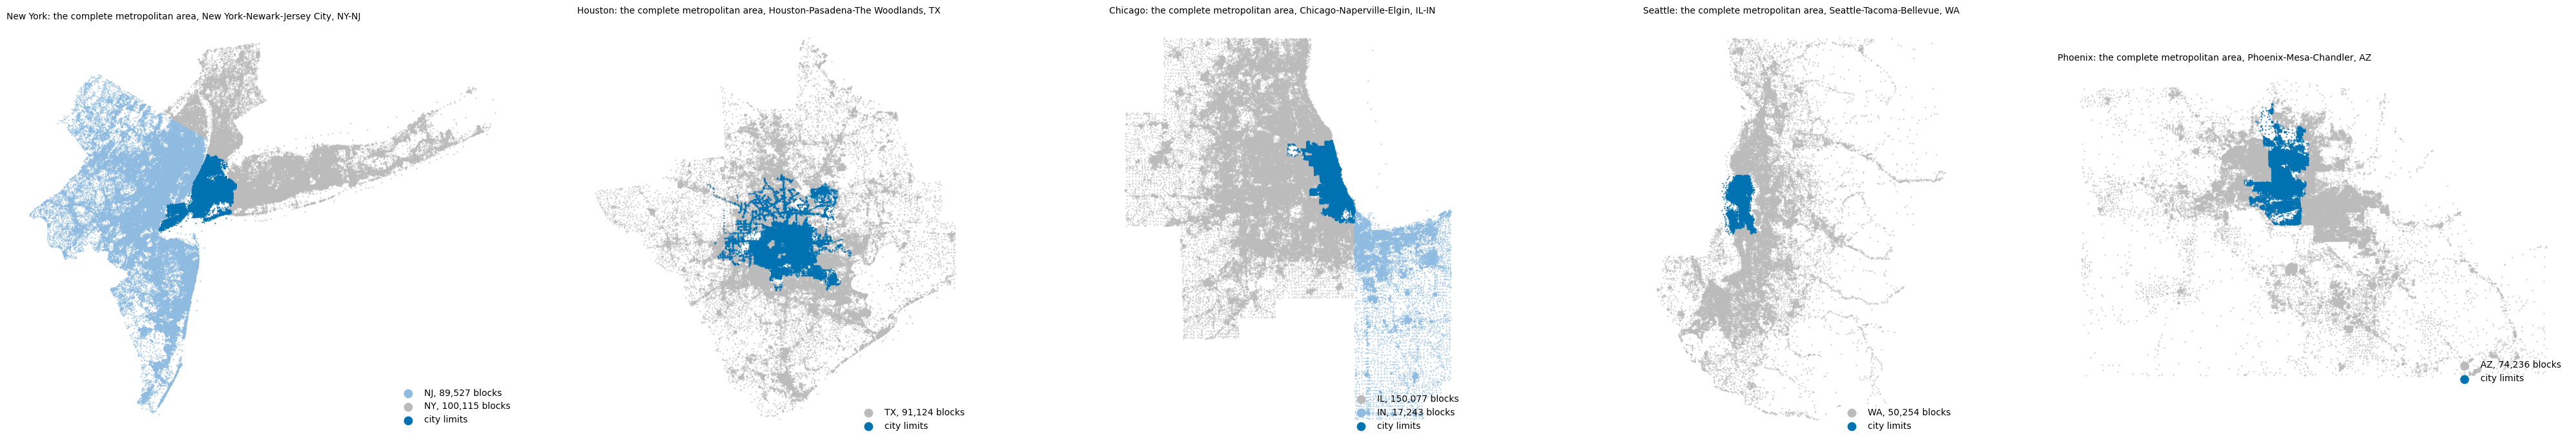

In [14]:
STATE_COLOURS = {"NY": "#bbbbbb", "NJ": "#8fbbe0", "TX": "#bbbbbb", "IL": "#bbbbbb", "IN": "#8fbbe0", "WI": "#c9a0dc", "WA": "#bbbbbb", "AZ": "#bbbbbb"}
figure, axes = plt.subplots(ncols=len(CITIES), figsize=(8 * len(CITIES), 7))
for axis, city in zip(axes, CITIES):
    blocks = metro[city]["blocks"]
    for state, part in blocks.groupby("state"):
        axis.scatter(part["blklondd"], part["blklatdd"], s=0.2, color=STATE_COLOURS[state], label=f"{state}, {len(part):,} blocks")
    in_place = blocks["stplc"] == definitions[city]["place"]
    axis.scatter(blocks.loc[in_place, "blklondd"], blocks.loc[in_place, "blklatdd"], s=0.2, color="#0072B2", label="city limits")
    axis.set_aspect(1 / np.cos(np.radians(blocks["blklatdd"].mean())))
    axis.legend(frameon=False, loc="lower right", markerscale=20)
    axis.set_title(f"{city}: the complete metropolitan area, {definitions[city]['cbsa_name']}", loc="left", fontsize=10)
    axis.set_axis_off()
figure.tight_layout()

for city in CITIES:
    folder = RESULTS / city.lower().replace(" ", "-")
    folder.mkdir(parents=True, exist_ok=True)
    metro[city]["blocks"].to_parquet(folder / f"lodes-metro-blocks-{YEAR}.parquet", index=False)
    workers = metro[city]["workers"]
    workers.loc[workers["home_inside"], ["w_geocode", "h_geocode", "S000"]].to_parquet(folder / f"lodes-metro-od-JT01-{YEAR}.parquet", index=False)
    print(city, "->", folder)